# Ejercicio 5: Regresión lineal múltiple — HOUSE3

## Enunciado

Considere un modelo para explicar y pronosticar el valor estimado de una muestra compuesta por 15 casas (en miles de dólares), con base en su tamaño (en metros cuadrados) y si cuentan con chimenea o no. Los datos están en el archivo `../Docs/HOUSE3.xls`.

## Resolución paso a paso

1. **Definir las variables.** `Value` es el valor de la casa en miles de dólares; `Size` es el tamaño registrado en el archivo; y `Fireplace` indica si la casa tiene chimenea. Se dispone de 15 observaciones.
2. **Codificar la variable categórica.** Se representa `Fireplace` mediante una variable indicadora: `Yes = 1` y `No = 0`. Así, el coeficiente correspondiente compara el valor medio de las casas con y sin chimenea, manteniendo fijo el tamaño.
3. **Ajustar el modelo múltiple.** Se estima por mínimos cuadrados $Value_i = \beta_0 + \beta_1 Size_i + \beta_2 Fireplace_i + \varepsilon_i$. El coeficiente de `Size` mide el cambio estimado en el valor por unidad de `Size`, manteniendo fija la chimenea.
4. **Interpretar y usar para pronosticar.** Se informan coeficientes, errores estándar, pruebas t, intervalos de confianza y $R^2$. Para ilustrar el uso del modelo, el código estima el valor medio y el intervalo de confianza y de predicción para casas con chimenea y sin chimenea al tamaño medio observado. Se distinguen ambos intervalos: el de confianza corresponde al valor medio, mientras que el de predicción para una casa individual es más ancho.
5. **Revisar los gráficos.** El gráfico de dispersión representa tamaño y valor, separando las casas por chimenea e incluyendo las rectas ajustadas; los gráficos de observados vs. ajustados, residuos y Q-Q ayudan a evaluar visualmente el modelo. Con solo 15 casas, la evaluación de supuestos es limitada. La independencia debe justificarse por el diseño de muestreo.

**Nota sobre unidades:** el enunciado indica metros cuadrados, pero la columna `Size` del libro no trae unidad ni escala y contiene valores entre 1.20 y 2.00. El análisis utiliza esos valores tal como aparecen; por lo tanto, el coeficiente se interpreta por unidad registrada en `Size`. Confirma la escala original antes de interpretar esa unidad literalmente como un metro cuadrado.

El modelo estima asociaciones y no demuestra que el tamaño o la presencia de una chimenea causen las diferencias de valor.

Archivo: C:\Users\Gasti\Desktop\MPG\Docs\HOUSE3.xls
Casas: 15 | Fireplace: No=0, Yes=1
Value está en miles de dólares. Size se usa en las unidades registradas en el archivo.


,Value,Size,Fireplace,Fireplace_code
0,84.4,2.00,Yes,1
1,77.4,1.71,No,0
2,75.7,1.45,No,0
3,85.9,1.76,Yes,1
4,79.1,1.93,No,0
5,70.4,1.20,Yes,1
6,75.8,1.55,Yes,1
7,85.9,1.93,Yes,1
8,78.5,1.59,Yes,1
9,79.2,1.50,Yes,1


,count,mean,std,min,25%,50%,75%,max
Value,15.0,79.560,4.819129,70.4,76.30,79.10,84.100,86.7
Size,15.0,1.662,0.235257,1.2,1.52,1.59,1.895,2.0


,Coeficiente,Error estándar,t,p-valor,IC 95% inferior,IC 95% superior
Intercepto,50.090489,4.351658,11.510668,7.679427e-08,40.609041,59.571937
Size (por unidad registrada),16.185834,2.574442,6.287124,4.024367e-05,10.576607,21.795061
Fireplace: Yes vs. No,3.852982,1.241223,3.104183,9.118854e-03,1.148591,6.557374


R² = 0.8111 | R² ajustado = 0.7796 | Error estándar residual = 2.263 miles de USD
Ecuación estimada: Value_hat = 50.090 + 16.186·Size + 3.853·Fireplace_code
Por cada unidad registrada adicional de Size, el valor estimado cambia 16.186 miles de USD, manteniendo Fireplace constante.
A igual Size, una casa con chimenea tiene un valor estimado 3.853 miles de USD distinto al de una sin chimenea.
IC 95% para la diferencia Yes-No: [1.149, 6.557] miles de USD; p-valor = 0.0091.

Pronósticos ilustrativos para Size medio = 1.662 (unidades registradas):
Fireplace=No: media estimada = 76.991 miles de USD
  IC 95% para la media: [74.784, 79.198] miles de USD
  Intervalo de predicción 95% para una casa: [71.590, 82.393] miles de USD
Fireplace=Yes: media estimada = 80.844 miles de USD
  IC 95% para la media: [79.285, 82.404] miles de USD
  Intervalo de predicción 95% para una casa: [75.674, 86.015] miles de USD


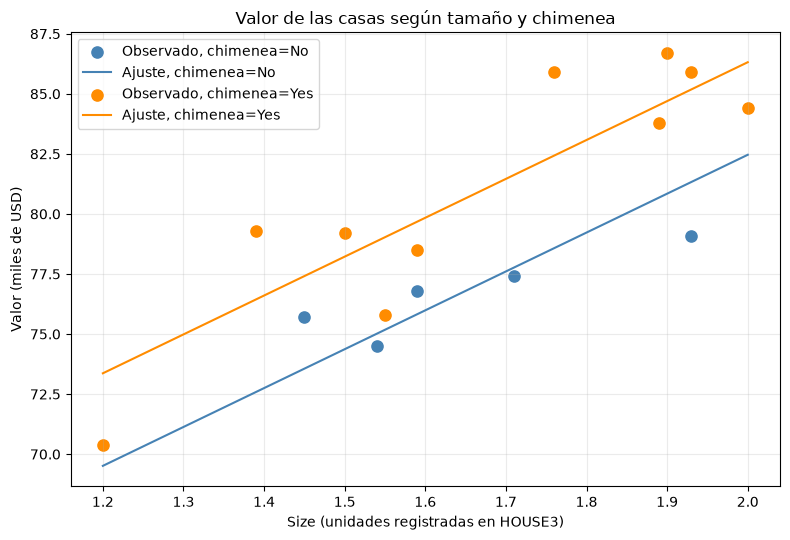

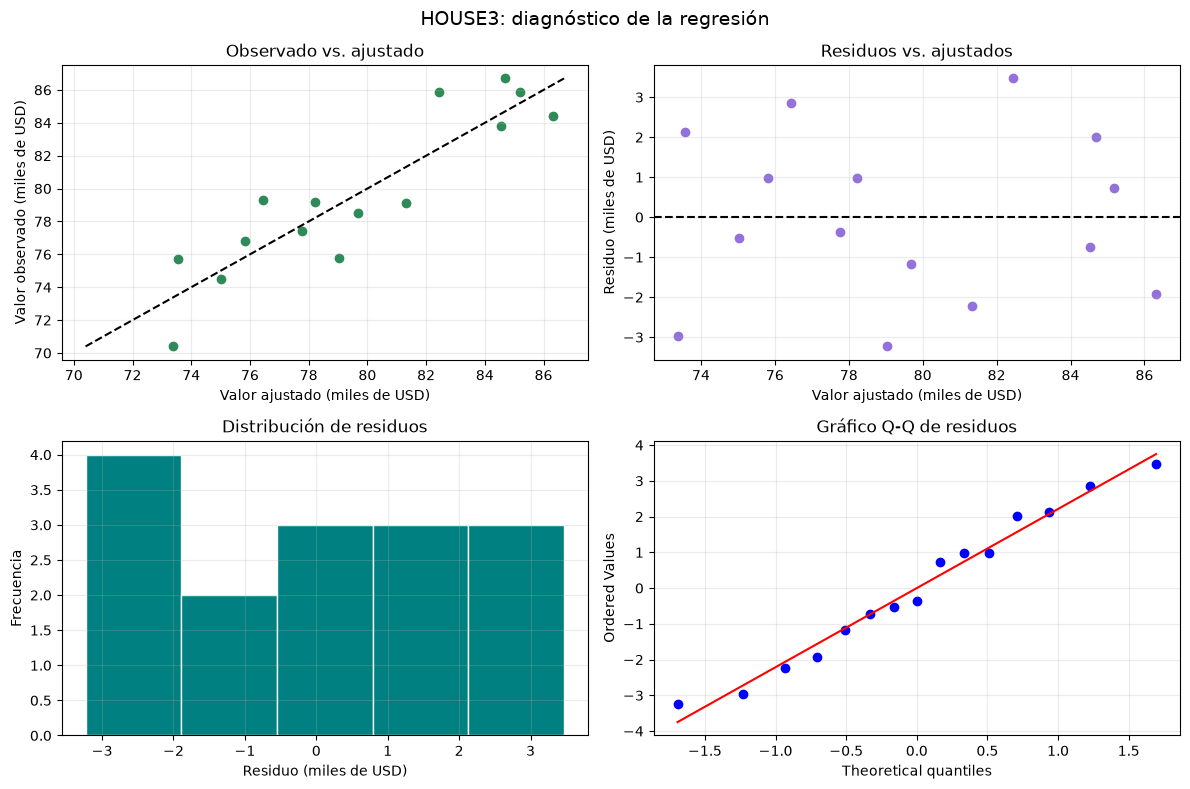

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Busca HOUSE3.xls desde la raíz del proyecto o desde Regresion_lineal.
rutas = [Path("Docs/HOUSE3.xls"), Path("../Docs/HOUSE3.xls")]
archivo = next((ruta for ruta in rutas if ruta.is_file()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró HOUSE3.xls. Comprueba que el archivo esté en la carpeta Docs del proyecto."
    )

datos = pd.read_excel(archivo)
columnas = ["Value", "Size", "Fireplace"]
faltantes = set(columnas).difference(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en HOUSE3.xls: {sorted(faltantes)}")
if len(datos) != 15 or datos[columnas].isna().any().any():
    raise ValueError("Se esperaban 15 observaciones completas en Value, Size y Fireplace.")
categorias = set(datos["Fireplace"].astype(str).str.strip())
if categorias != {"Yes", "No"}:
    raise ValueError(f"Se esperaban las categorías Yes y No en Fireplace; se encontraron {sorted(categorias)}.")

datos["Fireplace_code"] = datos["Fireplace"].astype(str).str.strip().map({"No": 0, "Yes": 1})
print(f"Archivo: {archivo.resolve()}")
print(f"Casas: {len(datos)} | Fireplace: No=0, Yes=1")
print("Value está en miles de dólares. Size se usa en las unidades registradas en el archivo.")
display(datos)
display(datos[["Value", "Size"]].describe().T)

# Modelo: Value = beta_0 + beta_1*Size + beta_2*Fireplace_code + error.
y = datos["Value"].to_numpy(dtype=float)
X = np.column_stack(
    [np.ones(len(datos)), datos["Size"].to_numpy(dtype=float), datos["Fireplace_code"].to_numpy(dtype=float)]
)
n, k = X.shape
gl_error = n - k
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
ajustados = X @ beta
residuos = y - ajustados
sse = float(residuos @ residuos)
mse = sse / gl_error
inv_xtx = np.linalg.inv(X.T @ X)
cov_beta = mse * inv_xtx
ee_beta = np.sqrt(np.diag(cov_beta))
t_beta = beta / ee_beta
p_beta = 2 * stats.t.sf(np.abs(t_beta), gl_error)
t_critico = stats.t.ppf(0.975, gl_error)
li_beta = beta - t_critico * ee_beta
ls_beta = beta + t_critico * ee_beta
r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
r2_ajustado = 1 - (1 - r2) * (n - 1) / gl_error

tabla = pd.DataFrame(
    {
        "Coeficiente": beta,
        "Error estándar": ee_beta,
        "t": t_beta,
        "p-valor": p_beta,
        "IC 95% inferior": li_beta,
        "IC 95% superior": ls_beta,
    },
    index=["Intercepto", "Size (por unidad registrada)", "Fireplace: Yes vs. No"],
)
display(tabla)
print(f"R² = {r2:.4f} | R² ajustado = {r2_ajustado:.4f} | Error estándar residual = {np.sqrt(mse):.3f} miles de USD")
print(f"Ecuación estimada: Value_hat = {beta[0]:.3f} + {beta[1]:.3f}·Size + {beta[2]:.3f}·Fireplace_code")
print(f"Por cada unidad registrada adicional de Size, el valor estimado cambia {beta[1]:.3f} miles de USD, manteniendo Fireplace constante.")
print(f"A igual Size, una casa con chimenea tiene un valor estimado {beta[2]:.3f} miles de USD distinto al de una sin chimenea.")
print(f"IC 95% para la diferencia Yes-No: [{li_beta[2]:.3f}, {ls_beta[2]:.3f}] miles de USD; p-valor = {p_beta[2]:.4f}.")

# Ejemplo de pronóstico al tamaño medio observado para cada categoría de chimenea.
size_ejemplo = float(datos["Size"].mean())
print(f"\nPronósticos ilustrativos para Size medio = {size_ejemplo:.3f} (unidades registradas):")
for tiene_chimenea, etiqueta in [(0, "No"), (1, "Yes")]:
    x0 = np.array([1.0, size_ejemplo, float(tiene_chimenea)])
    media = float(x0 @ beta)
    h0 = float(x0 @ inv_xtx @ x0)
    ee_media = np.sqrt(mse * h0)
    ee_prediccion = np.sqrt(mse * (1 + h0))
    ic_media = (media - t_critico * ee_media, media + t_critico * ee_media)
    ip_individual = (media - t_critico * ee_prediccion, media + t_critico * ee_prediccion)
    print(f"Fireplace={etiqueta}: media estimada = {media:.3f} miles de USD")
    print(f"  IC 95% para la media: [{ic_media[0]:.3f}, {ic_media[1]:.3f}] miles de USD")
    print(f"  Intervalo de predicción 95% para una casa: [{ip_individual[0]:.3f}, {ip_individual[1]:.3f}] miles de USD")

# Relación entre tamaño y valor, con líneas ajustadas según chimenea.
size_grid = np.linspace(datos["Size"].min(), datos["Size"].max(), 100)
fig, ax = plt.subplots(figsize=(8, 5.5))
colores = {"No": "steelblue", "Yes": "darkorange"}
for tiene_chimenea, etiqueta in [(0, "No"), (1, "Yes")]:
    grupo = datos[datos["Fireplace_code"] == tiene_chimenea]
    ax.scatter(grupo["Size"], grupo["Value"], color=colores[etiqueta], s=65, label=f"Observado, chimenea={etiqueta}")
    linea = beta[0] + beta[1] * size_grid + beta[2] * tiene_chimenea
    ax.plot(size_grid, linea, color=colores[etiqueta], label=f"Ajuste, chimenea={etiqueta}")
ax.set(title="Valor de las casas según tamaño y chimenea", xlabel="Size (unidades registradas en HOUSE3)", ylabel="Valor (miles de USD)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Diagnóstico visual de los residuos.
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].scatter(ajustados, y, color="seagreen")
limites = [min(y.min(), ajustados.min()), max(y.max(), ajustados.max())]
ax[0, 0].plot(limites, limites, "k--")
ax[0, 0].set(title="Observado vs. ajustado", xlabel="Valor ajustado (miles de USD)", ylabel="Valor observado (miles de USD)")
ax[0, 1].scatter(ajustados, residuos, color="mediumpurple")
ax[0, 1].axhline(0, color="black", linestyle="--")
ax[0, 1].set(title="Residuos vs. ajustados", xlabel="Valor ajustado (miles de USD)", ylabel="Residuo (miles de USD)")
ax[1, 0].hist(residuos, bins="auto", color="teal", edgecolor="white")
ax[1, 0].set(title="Distribución de residuos", xlabel="Residuo (miles de USD)", ylabel="Frecuencia")
stats.probplot(residuos, dist="norm", plot=ax[1, 1])
ax[1, 1].set(title="Gráfico Q-Q de residuos")
for eje in ax.flat:
    eje.grid(alpha=0.25)
fig.suptitle("HOUSE3: diagnóstico de la regresión", fontsize=14)
fig.tight_layout()
plt.show()

## Conclusión

El modelo estima el valor de las casas en función del tamaño registrado y de si tienen chimenea. La tabla de resultados permite interpretar el cambio asociado a cada unidad de tamaño y la diferencia ajustada entre casas con `Fireplace=Yes` y `Fireplace=No`. El código incluye ejemplos de estimación media e intervalos para ambas categorías al tamaño medio observado; son ilustrativos y no una condición solicitada explícitamente por el enunciado. Antes de interpretar el coeficiente de `Size` como valor por metro cuadrado, hay que confirmar la escala que representa esa columna en la fuente original.